# Projeto de Detecção de Fraude Bancária



## 1. Objetivo



Desenvolver um modelo de Machine Learning capaz de identificar transações financeiras fraudulentas.



Além da construção do modelo, o projeto busca identificar padrões de fraude por meio da análise exploratória dos dados, avaliando o comportamento das transações legítimas e fraudulentas.



## 2. Entendimento dos Dados



O dataset contém informações de transações realizadas por cartões de crédito.



Características da base:



- 284.807 transações

- 31 variáveis

- Variáveis V1 a V28 anonimizadas

- Variável Amount representando o valor da transação

- Variável Time representando o tempo da transação

- Variável Class representando o alvo do problema:

- 0 = Transação legítima

- 1 = Fraude

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("creditcard.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


## 3. Qualidade dos Dados



A análise inicial mostrou que:



- Não existem valores nulos na base de dados.

- Todas as variáveis são numéricas.

- O dataset possui 284.807 registros válidos.

- Não foi necessária nenhuma etapa de imputação ou remoção de registros.

In [6]:
df['Class'].value_counts()

,count
Class,
0,284315
1,492


In [7]:
df['Class'].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


## 4. Análise da Variável Alvo



A variável Class apresenta forte desbalanceamento.



Resultados observados:



- Transações legítimas: 284.315 registros

- Fraudes: 492 registros



Isso significa que apenas aproximadamente 0,17% das transações são fraudulentas.



Esse cenário é comum em problemas reais de detecção de fraude e exige atenção especial durante a etapa de modelagem.

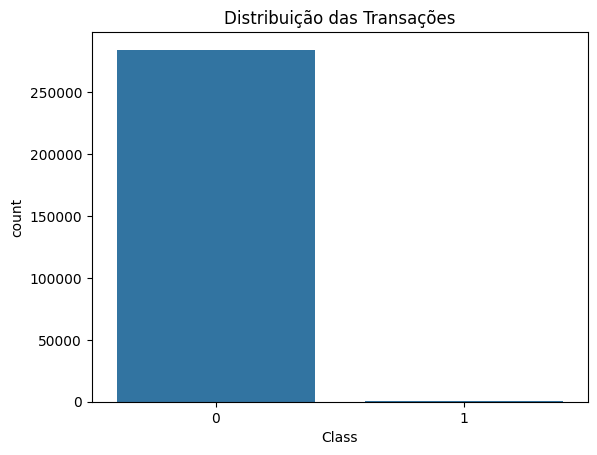

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Class', data=df)

plt.title('Distribuição das Transações')
plt.show()

In [9]:
df.info()
df.isnull().sum()
df['Class'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

,count
Class,
0,284315
1,492


In [10]:
492/284807*100

0.1727485630620034

## 4. Análise da Variável Alvo



A variável Class apresenta forte desbalanceamento.



Resultados observados:



- Transações legítimas: 284.315 registros

- Fraudes: 492 registros



Isso significa que apenas aproximadamente 0,17% das transações são fraudulentas.



Esse cenário é comum em problemas reais de detecção de fraude e exige atenção especial durante a etapa de modelagem.

In [11]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [12]:
df["Amount"].describe()

,Amount
count,284807.000000
mean,88.349619
std,250.120109
min,0.000000
25%,5.600000
50%,22.000000
75%,77.165000
max,25691.160000


## 5. Análise do Valor das Transações



### Estatísticas Descritivas



As principais estatísticas da variável Amount são apresentadas a seguir:



- Média: 88,35

- Mediana: 22,00

- Desvio padrão: 250,12

- Valor máximo: 25.691,16



Observou-se uma distribuição assimétrica à direita, indicando a presença de transações de valor significativamente superior à maioria das operações registradas.



A diferença entre média e mediana sugere a existência de valores extremos (outliers) que elevam a média da distribuição.



### Análise dos Percentis



Observou-se que:



- 25% das transações possuem valor inferior a 5,60;

- 50% das transações possuem valor inferior a 22,00;

- 75% das transações possuem valor inferior a 77,17;

- 99% das transações possuem valor inferior a 1.017,97.



Apesar disso, a maior transação registrada atingiu o valor de 25.691,16, evidenciando a presença de outliers extremos.



Esses resultados indicam uma distribuição fortemente assimétrica à direita, característica comum em transações financeiras, nas quais a maioria das operações apresenta valores relativamente baixos e uma pequena parcela concentra valores muito elevados.



### Insight de Negócio



A concentração da maior parte das transações em valores baixos, combinada com a existência de operações de valor extremamente elevado, sugere a necessidade de monitoramento especial para transações fora do padrão habitual.



Esse comportamento pode ser relevante para modelos de detecção de fraude, uma vez que operações atípicas frequentemente apresentam características distintas do comportamento normal dos clientes.

In [13]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


## 6. Comparação entre Transações Legítimas e Fraudulentas



A análise da variável Amount por classe indicou diferenças relevantes entre transações legítimas e fraudulentas.



Observou-se que as transações classificadas como fraude apresentaram valor médio superior ao das transações legítimas.



Além disso, o desvio padrão mais elevado sugere maior variabilidade nos valores das fraudes, indicando que esse tipo de ocorrência pode acontecer em diferentes faixas de valor.



Esses resultados sugerem que o valor da transação pode contribuir para a identificação de operações suspeitas.

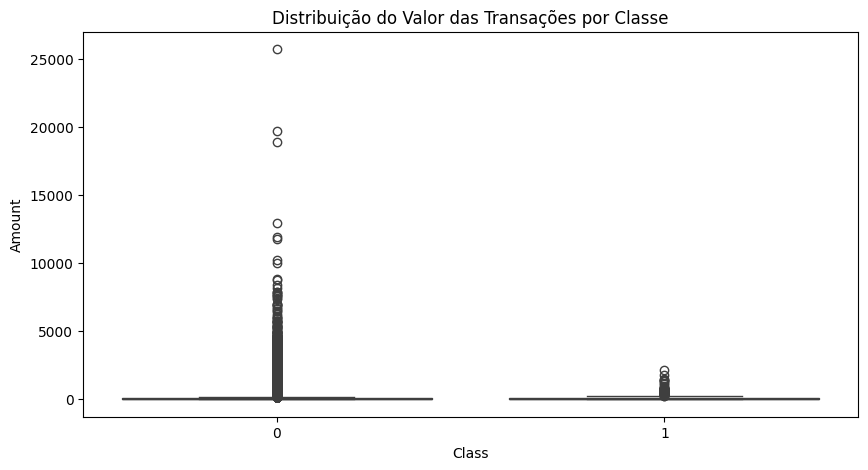

In [14]:
plt.figure(figsize=(10, 5))

sns.boxplot(x='Class', y='Amount', data=df)

plt.title('Distribuição do Valor das Transações por Classe')

plt.show()

In [15]:
df['Amount'].quantile([0.25, 0.5, 0.75, 0.95, 0.99])

,Amount
0.25,5.600
0.50,22.000
0.75,77.165
0.95,365.000
0.99,1017.970


In [16]:
correlation = df.corr()

correlation['Class'].sort_values(ascending=False)

,Class
Class,1.000000
V11,0.154876
V4,0.133447
V2,0.091289
V21,0.040413
V19,0.034783
V20,0.020090
V8,0.019875
V27,0.017580
V28,0.009536


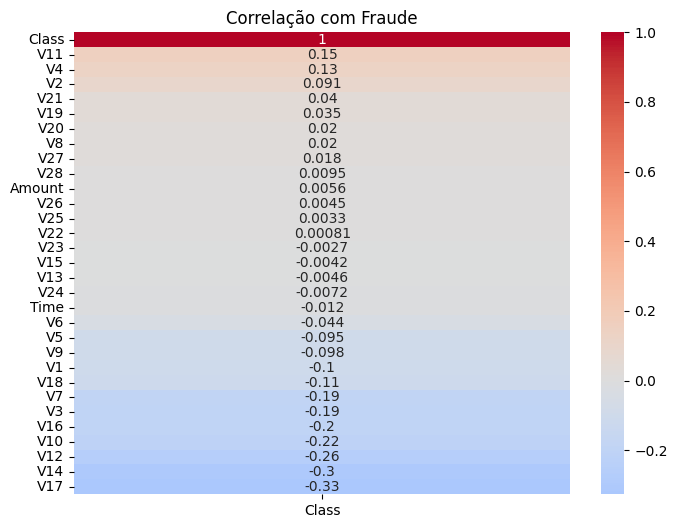

In [17]:
plt.figure(figsize=(8,6))

corr_class = df.corr()[['Class']].sort_values(
by='Class',
ascending=False
)

sns.heatmap(
corr_class,
annot=True,
cmap='coolwarm',
center=0

)
plt.title('Correlação com Fraude')
plt.show()

## 7. Análise de Correlação

### Correlação com a Variável Alvo



Foi calculada a correlação entre todas as variáveis do conjunto de dados e a variável alvo (Class).



As variáveis V17, V14 e V12 apresentaram as maiores magnitudes de correlação com a variável alvo, sugerindo maior capacidade de diferenciar transações fraudulentas das legítimas.



Embora as correlações observadas sejam predominantemente negativas, a direção da correlação não reduz sua importância para o modelo. O fator mais relevante é a intensidade da associação com a ocorrência de fraude.



Esses resultados indicam que tais variáveis poderão ter papel importante durante a etapa de modelagem preditiva.

## 8. Preparação dos Dados



Nesta etapa, os dados serão separados entre variáveis explicativas (X) e variável alvo (y).



A variável Class representa a ocorrência de fraude e será utilizada como variável alvo do modelo.

In [18]:
X = df.drop('Class', axis=1)

y= df['Class']

In [19]:
print(X.shape)
print(y.shape)

(284807, 30)
(284807,)


In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


## 10. Avaliação do Balanceamento das Classes

Após a divisão entre treino e teste, verificou-se que a proporção entre transações legítimas e fraudulentas foi preservada.

Conjunto de treino:

- Transações legítimas: 227.451
- Fraudes: 394

Conjunto de teste:

- Transações legítimas: 56.864
- Fraudes: 98

A manutenção da distribuição original das classes foi garantida por meio do parâmetro `stratify=y`, permitindo uma avaliação mais representativa do desempenho dos modelos.

Entretanto, observa-se que o problema continua altamente desbalanceado, visto que as fraudes representam aproximadamente 0,17% das transações.

## 9. Divisão entre Treino e Teste

O conjunto de dados foi dividido em conjuntos de treino e teste.

O conjunto de treino será utilizado para o treinamento dos modelos de Machine Learning, enquanto o conjunto de teste será utilizado para avaliar o desempenho do modelo em dados não vistos anteriormente.

Foi utilizada uma proporção de 80% para treino e 20% para teste.

Além disso, foi aplicado o parâmetro `stratify=y` para preservar a proporção original entre transações legítimas e fraudulentas em ambos os conjuntos.

In [22]:
print(X_train.shape)
print(X_test.shape)

(227845, 30)
(56962, 30)


In [23]:
y_train.value_counts()

,count
Class,
0,227451
1,394


In [24]:
y_test.value_counts()

,count
Class,
0,56864
1,98


## 11. Primeiro Modelo: Regressão Logística

A Regressão Logística foi utilizada como modelo inicial de classificação para identificar transações fraudulentas.

Esse modelo foi escolhido por sua simplicidade, interpretabilidade e ampla utilização em problemas de classificação binária.

Além disso, ele será utilizado como baseline para comparação com modelos mais avançados nas etapas seguintes.

In [25]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [26]:
y_pred=model.predict(X_test)

In [27]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.84      0.69      0.76        98

    accuracy                           1.00     56962
   macro avg       0.92      0.85      0.88     56962
weighted avg       1.00      1.00      1.00     56962



### Avaliação do Modelo

O modelo apresentou os seguintes resultados para a classe de fraude:

- Precision: 0,84
- Recall: 0,69
- F1-Score: 0,76

Os resultados indicam que, quando o modelo classifica uma transação como fraude, ele está correto em aproximadamente 84% dos casos.

Além disso, o modelo conseguiu identificar cerca de 69% das fraudes presentes no conjunto de teste.

Como problemas de fraude financeira priorizam a identificação do maior número possível de ocorrências suspeitas, a métrica Recall possui especial relevância para avaliação do desempenho do modelo.

## 12. Matriz de Confusão

A matriz de confusão permite visualizar os acertos e erros do modelo durante a classificação das transações.

Essa análise é especialmente importante em problemas de fraude financeira, pois evidencia quantas fraudes foram corretamente identificadas e quantas deixaram de ser detectadas.

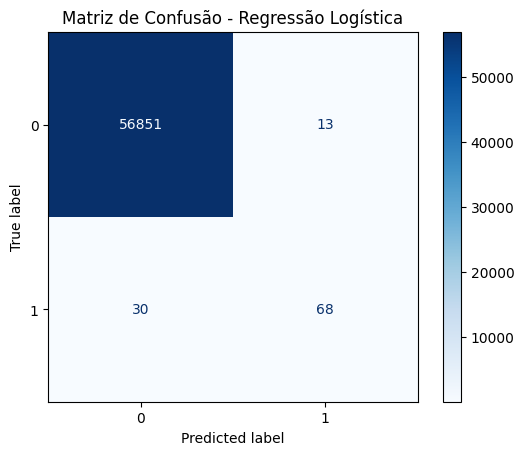

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(cmap='Blues')

plt.title('Matriz de Confusão - Regressão Logística')
plt.show()

### Interpretação da Matriz de Confusão

A matriz de confusão demonstrou que o modelo classificou corretamente 56.851 transações legítimas e identificou 68 fraudes.

Foram observados apenas 13 falsos positivos, indicando baixa incidência de alertas incorretos para clientes legítimos.

Por outro lado, 30 fraudes não foram detectadas pelo modelo, representando casos de falso negativo. Em cenários de prevenção a fraudes, esse tipo de erro é particularmente relevante, pois pode resultar em perdas financeiras para a instituição.

Os resultados reforçam a necessidade de avaliar estratégias adicionais para aumentar a capacidade de detecção das fraudes, especialmente por meio da melhoria da métrica Recall.

## 13. Tratamento do Desbalanceamento com SMOTE

O conjunto de dados apresenta forte desbalanceamento entre transações legítimas e fraudulentas.

Para reduzir esse problema foi utilizada a técnica SMOTE (Synthetic Minority Oversampling Technique), responsável por gerar exemplos sintéticos da classe minoritária durante o treinamento dos modelos.

O objetivo é aumentar a capacidade do algoritmo em identificar padrões associados às fraudes.

In [29]:
from imblearn.over_sampling import SMOTE

In [30]:
smote = SMOTE(random_state=42)

In [31]:
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [32]:
y_train_smote.value_counts()

,count
Class,
0,227451
1,227451


## 13. Tratamento do Desbalanceamento com SMOTE

O conjunto de dados apresenta forte desbalanceamento entre transações legítimas e fraudulentas.

Para reduzir esse problema, foi utilizada a técnica SMOTE (Synthetic Minority Oversampling Technique), responsável por gerar exemplos sintéticos da classe minoritária durante o treinamento.

O objetivo é permitir que o modelo aprenda com mais eficiência os padrões associados às transações fraudulentas.

In [33]:
from imblearn.over_sampling import SMOTE

In [34]:
smote = SMOTE(random_state=42)

In [35]:
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [36]:
y_train_smote.value_counts()

,count
Class,
0,227451
1,227451


### Resultado do Balanceamento

A aplicação do SMOTE permitiu equilibrar a distribuição das classes no conjunto de treinamento.

Antes do balanceamento, existiam 227.451 transações legítimas e apenas 394 fraudes.

Após a aplicação da técnica, ambas as classes passaram a possuir 227.451 registros, permitindo que o modelo tivesse acesso a uma quantidade equivalente de exemplos durante o treinamento.

Esse procedimento busca aumentar a capacidade de identificação das fraudes, reduzindo o viés causado pelo forte desbalanceamento da base original.

In [37]:
from sklearn.linear_model import LogisticRegression

model_smote = LogisticRegression(max_iter=1000)

model_smote.fit(
    X_train_smote,
    y_train_smote
)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [38]:
y_pred_smote = model_smote.predict(X_test)

In [39]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_smote
))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.90      0.21        98

    accuracy                           0.99     56962
   macro avg       0.56      0.94      0.60     56962
weighted avg       1.00      0.99      0.99     56962



## 14. Comparação dos Resultados

A aplicação do SMOTE aumentou significativamente a capacidade do modelo em identificar transações fraudulentas.

O Recall da classe de fraude evoluiu de 0,69 para 0,90, indicando que um número maior de fraudes passou a ser detectado.

Por outro lado, a Precision apresentou queda expressiva, passando de 0,84 para 0,12. Isso indica aumento considerável da quantidade de falsos positivos gerados pelo modelo.

Os resultados demonstram o trade-off existente entre maximizar a detecção de fraudes e reduzir alertas incorretos.

A escolha do modelo mais adequado depende do contexto de negócio e dos custos associados aos diferentes tipos de erro.

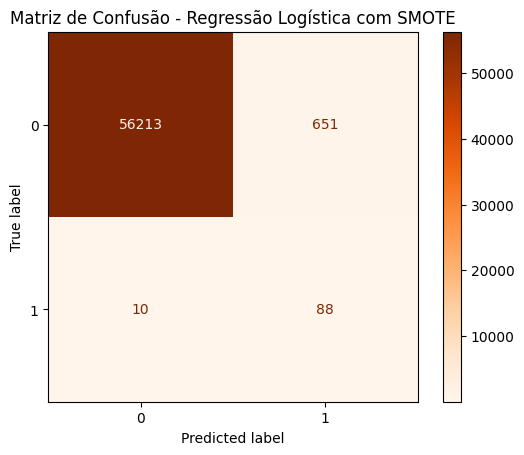

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_smote = confusion_matrix(y_test, y_pred_smote)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote
)

disp.plot(cmap='Oranges')

plt.title('Matriz de Confusão - Regressão Logística com SMOTE')
plt.show()

## 15. Modelo Random Forest

Após a avaliação da Regressão Logística, foi utilizado o algoritmo Random Forest para verificar a capacidade de um modelo mais robusto em identificar transações fraudulentas.

O Random Forest utiliza múltiplas árvores de decisão para realizar as previsões, reduzindo a variância e aumentando a capacidade de generalização do modelo.

In [41]:
from sklearn.ensemble import RandomForestClassifier

In [42]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [43]:
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [44]:
y_pred_rf = rf.predict(X_test)

In [45]:
from sklearn.metrics import classification_report

In [46]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



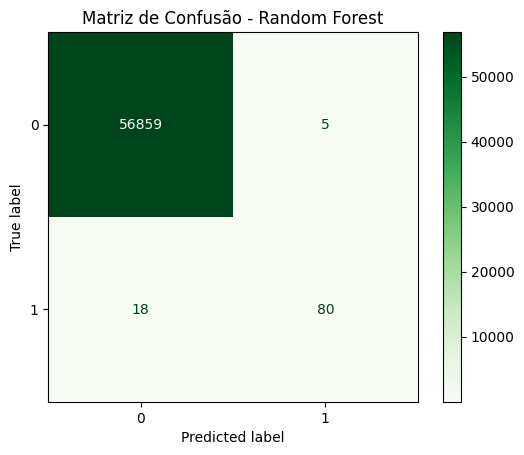

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf
)

disp.plot(cmap='Greens')

plt.title('Matriz de Confusão - Random Forest')
plt.show()

| Modelo              | Precision | Recall   | F1       |
| ------------------- | --------- | -------- | -------- |
| Regressão Logística | 0.84      | 0.69     | 0.76     |
| Regressão + SMOTE   | 0.12      | 0.90     | 0.21     |
| Random Forest       | **0.94**  | **0.82** | **0.87** |


## 16. Avaliação do Modelo Random Forest

O modelo Random Forest apresentou desempenho superior ao observado nos modelos anteriores.

Resultados obtidos:

- Precision: 0,94
- Recall: 0,82
- F1-Score: 0,87

O modelo demonstrou alta capacidade de identificar transações fraudulentas, mantendo ao mesmo tempo uma baixa taxa de falsos positivos.

Em comparação com a Regressão Logística, observou-se melhora tanto na precisão dos alertas quanto na capacidade de detecção das fraudes.

Esses resultados indicam que o Random Forest é capaz de capturar relações mais complexas entre as variáveis, produzindo previsões mais eficazes para o problema analisado.

In [51]:
importances = pd.DataFrame({
    'Variavel': X.columns,
    'Importancia': rf.feature_importances_
})

importances = importances.sort_values(
    by='Importancia',
    ascending=False
)

importances.head(10)

,Variavel,Importancia
17,V17,0.170325
14,V14,0.136363
12,V12,0.133326
10,V10,0.074073
16,V16,0.071792
11,V11,0.045277
9,V9,0.031127
4,V4,0.030496
18,V18,0.028156
7,V7,0.024627


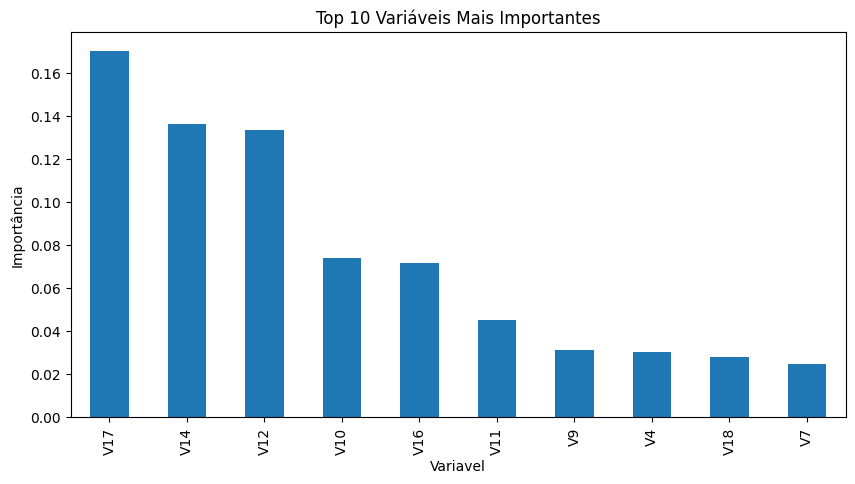

In [52]:
importances.head(10).plot(
    x='Variavel',
    y='Importancia',
    kind='bar',
    figsize=(10,5),
    legend=False
)

plt.title('Top 10 Variáveis Mais Importantes')
plt.ylabel('Importância')
plt.show()

## 17. Importância das Variáveis

Foi realizada a análise de importância das variáveis utilizando o modelo Random Forest.

Os resultados indicaram que algumas variáveis apresentaram contribuição significativamente maior para a identificação de transações fraudulentas.

Observou-se consistência entre os resultados da análise de correlação e das importâncias calculadas pelo Random Forest, sugerindo que determinadas variáveis possuem elevada capacidade discriminatória para o problema estudado.

A análise das importâncias contribui para a interpretação do modelo e auxilia na compreensão dos fatores mais relevantes para a detecção de fraudes.

## 18. Conclusão

O presente projeto teve como objetivo desenvolver modelos capazes de identificar transações financeiras fraudulentas.

A análise exploratória revelou um forte desbalanceamento entre as classes, com apenas 0,17% das transações classificadas como fraude.

Inicialmente foi treinado um modelo de Regressão Logística, que alcançou Recall de 69% e Precision de 84%.

Posteriormente foi aplicada a técnica SMOTE para balanceamento das classes. Embora o Recall tenha aumentado para 90%, observou-se uma redução significativa da Precision, gerando elevada quantidade de falsos positivos.

Por fim, foi implementado o modelo Random Forest, que apresentou o melhor equilíbrio entre capacidade de detecção e precisão dos alertas.

Resultados do modelo final:

- Precision: 94%
- Recall: 82%
- F1-Score: 87%

Além disso, as variáveis V17, V14 e V12 foram identificadas como os atributos mais relevantes para a detecção de fraudes.

Dessa forma, o Random Forest foi considerado o modelo mais adequado para o problema analisado, apresentando desempenho superior aos demais modelos avaliados.